# Real or Fake Image Recognition Task Using a Convolutional Neural Network

**APOAI2025 Mock Competition Question 2**
For this question, I built a model that receives a colored image and predicts whether it is **real (0)** or **generated (1)**. This notebook includes the complete code and the actual results from running it using `CIFAR10's "real"` images and a `diffused model's "fake"` images.

# 1. The task and approach

The supplied images on the two folders are 32 pixels wide and 32 pixels high wherein each pixel has red, green, and blue values. I used a **convolutional neural network (CNN)** which is the most appropriate model for this machine learning task as it elarns small image patterns and combines them to make a decision.

I used a small model to balance the image-classification task wherein the model proddudces only `two scores` in which the larger score determines its actual prediction.

# 2. Setup of the model

| Setting | Value | 
| --- | --- | 
| Maximum development epochs | 50 |
| Batch size | 64 |
| Starting learning rate | 0.001 |
| Weight penalty | 0.01 |
| Seed | 42 |
| CPU threads | 4 |

These are the chosen starting settings with the help of an LLM's suggestion. For reference, these are the suggested values: https://chatgpt.com/share/6acf7100-ab18-83ec-8341-f8193559edca.

In [29]:
import math
import random
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch import nn
from IPython.display import Markdown, display

PART_FOLDER = Path('/Users/davidfrancisco/Documents/ICAIC_Outputs/Question2')
DATA_DIR = PART_FOLDER / 'train_v1'
OUTPUT_DIR = PART_FOLDER

settings = SimpleNamespace(epochs=40, batch_size=64, learning_rate=0.001, seed=42, threads=4)
torch.set_num_threads(settings.threads)
torch.use_deterministic_algorithms(True)
print('Image folder:', DATA_DIR)
print('Output folder:', OUTPUT_DIR)

Image folder: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question2/train_v1
Output folder: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question2


## 3. Read and prepare the images

I loaded the supplied 32 × 32 images and assigned label **0** to real images in `cifar` and label **1** to generated images in `uvit`. Then, I converted the images to RGB and divided pixel values by 255 to scale them from **0–255** to **0–1** so its smaller and consistenly scaled to make training easier to manage.

The image tensor has shape `(10000, 3, 32, 32)`: 10,000 images, three colour channels, and 32 × 32 pixels. Training processes up to 64 images per batch.

In [30]:
def read_data(folder):
    images = []
    labels = []
    for label, name in enumerate(('cifar', 'uvit')):
        for path in sorted((folder / name).glob('*.png')):
            with Image.open(path) as original:
                image = original.convert('RGB')
                pixels = torch.frombuffer(bytearray(image.tobytes()), dtype=torch.uint8)
                pixels = pixels.reshape(32, 32, 3).permute(2, 0, 1)
                images.append(pixels.float() / 255.0)
            labels.append(label)
    return torch.stack(images), torch.tensor(labels, dtype=torch.long)

images, labels = read_data(DATA_DIR)
counts = torch.bincount(labels, minlength=2)
print(f'Labeled images: {len(images):,}')
print(f'Real: {counts[0].item():,}; generated: {counts[1].item():,}')
print('Image shape:', tuple(images.shape))

Labeled images: 10,000
Real: 5,000; generated: 5,000
Image shape: (10000, 3, 32, 32)


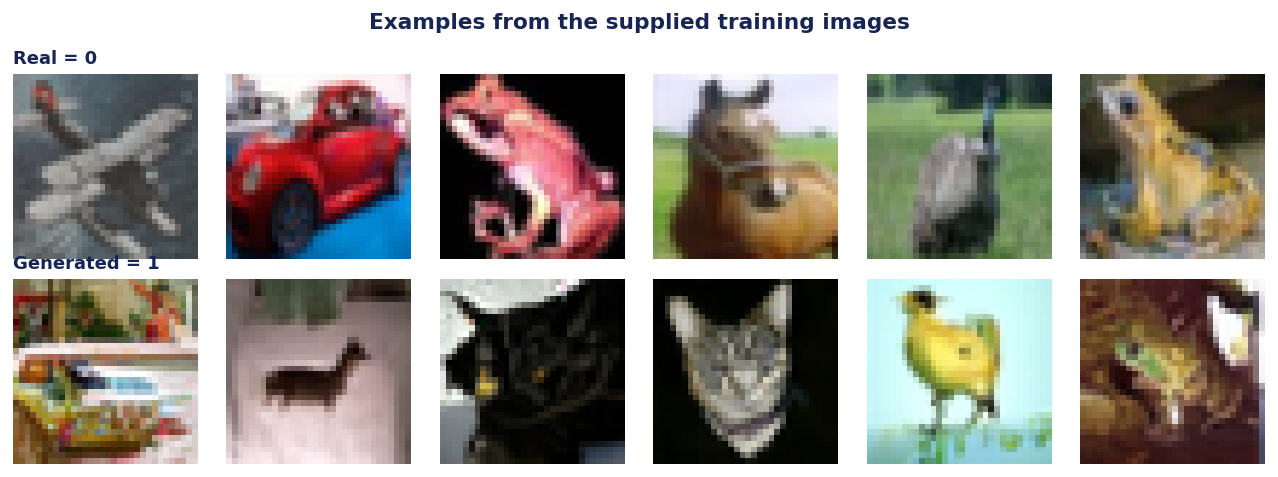

In [31]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.7))
for label, name in enumerate(('Real = 0', 'Generated = 1')):
    indices = (labels == label).nonzero().flatten()[:6]
    for column, index in enumerate(indices.tolist()):
        axes[label, column].imshow(images[index].permute(1, 2, 0))
        axes[label, column].set_axis_off()
        if column == 0:
            axes[label, column].set_title(name, fontsize=10, loc='left')
fig.suptitle('Examples from the supplied training images', fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_image_examples.png', bbox_inches='tight')
plt.show()
plt.close(fig)

# 4. Seperate images for choosing and checking

We know that a **label** is the known answer and based from the problem's instructions:

10,000 labeled images are splitted into two:
- 8,000 development images = 6,400 to learn the weights and 1,600 to choose the number of training passes
- 2,000 is kept for the final local check

The split then chooses about 20% of the real images and 20% of the generated images seperately which preserves the real/generated mix using the given seed I setup from the start.

In [32]:
def split_data(indices, labels, seed):
    rng = random.Random(seed)
    answers = labels.tolist()
    training = []
    holdout = []
    for label in (0, 1):
        group = [index for index in indices if answers[index] == label]
        rng.shuffle(group)
        count = round(0.2 * len(group))
        holdout.extend(group[:count])
        training.extend(group[count:])
    rng.shuffle(training)
    rng.shuffle(holdout)
    return (torch.tensor(training), torch.tensor(holdout))

development, holdout = split_data(list(range(len(labels))), labels, settings.seed)
training, validation = split_data(development.tolist(), labels, settings.seed + 1)
print(f'Learn weights: {len(training):,}')
print(f'Choose epoch count: {len(validation):,}')
print(f'Final local check: {len(holdout):,}')

Learn weights: 6,400
Choose epoch count: 1,600
Final local check: 2,000


# 5. Build the Convoluted Neural Network

1. Input are the 3 colors (RGB) which has a shape of `3 x 32 x 32`
2. It gets forwarded to Convolution 1 + ReLU and learns 32 small-pattern responses while replacing negative responses with 0 to add non-linearity. It's shape is now `32 x 32 x 32`
3. Max Pooled the response for the first time which gets the largest response in each 2 x 2 area which now updates the shape to `32 x 16 x 16`
4. It gets forwarded to Convolution 2 + ReLU which combines the responses into 64 furger patters which gives a shape of `64 x 16 x 16`
5. Max pooled the response again to reduce the grid again to its half making it a shape of `64 x 8 x 8`
6. Flatten the grid values into one row which giveds a total of `4,096` values
7. I then make it linear to calculate one final score for each answer.

In [33]:
class MyModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 8 * 8, 2)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        x = x.flatten(1)
        x = self.fc1(x)
        return x

example_model = MyModel()
print(example_model)

MyModel(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=2, bias=True)
)


# 6. Train and choose the stopping epoch

In [34]:
@torch.no_grad()
def evaluate(model, images, labels, batch_size):
    model.eval()
    total_loss = 0.0
    correct = 0
    confusion = torch.zeros(2, 2, dtype=torch.long)
    for start in range(0, len(images), batch_size):
        batch_images = images[start:start + batch_size]
        batch_labels = labels[start:start + batch_size]
        scores = model(batch_images)
        loss = nn.CrossEntropyLoss()(scores, batch_labels)
        predictions = scores.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total_loss += loss.item() * len(batch_labels)
        for actual in (0, 1):
            for predicted in (0, 1):
                confusion[actual, predicted] += ((batch_labels == actual) & (predictions == predicted)).sum()
    return {'accuracy': correct / len(labels), 'cross_entropy': total_loss / len(labels), 'correct': correct, 'total': len(labels), 'confusion_matrix': confusion.tolist()}

def fit(images, labels, epochs, args, validation=None):
    torch.manual_seed(args.seed)
    model = MyModel()
    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate, weight_decay=0.0001)
    loss_function = nn.CrossEntropyLoss()
    generator = torch.Generator().manual_seed(args.seed + 1000)
    best_key = None
    best_epoch = epochs
    best_metrics = None
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        learning_rate = args.learning_rate * (0.1 + 0.9 * (1 + math.cos(math.pi * (epoch - 1) / args.epochs)) / 2)
        optimizer.param_groups[0]['lr'] = learning_rate
        order = torch.randperm(len(images), generator=generator)
        total_loss = 0.0
        for start in range(0, len(images), args.batch_size):
            batch = order[start:start + args.batch_size]
            batch_images = images[batch]
            flip = torch.rand(len(batch), generator=generator) < 0.5
            batch_images[flip] = batch_images[flip].flip(3)
            optimizer.zero_grad(set_to_none=True)
            scores = model(batch_images)
            loss = loss_function(scores, labels[batch])
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch)
        record = {'epoch': epoch, 'training_loss': total_loss / len(images)}
        if validation is not None:
            metrics = evaluate(model, *validation, args.batch_size)
            record['validation'] = metrics
            key = (metrics['accuracy'], -metrics['cross_entropy'])
            if best_key is None or key > best_key:
                best_key = key
                best_epoch = epoch
                best_metrics = metrics
        history.append(record)
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            message = f'Epoch {epoch}/{epochs}: training loss={record['training_loss']:.6f}'
            if validation is not None:
                message += f'; validation accuracy={metrics['accuracy']:.2%}'
            print(message, flush=True)
    model.eval()
    return (model, best_epoch, best_metrics, history)


In [35]:
print('Choosing the epoch count using only the validation group:')
_, chosen_epoch, chosen_metrics, history = fit(
    images[training], labels[training], settings.epochs, settings,
    validation=(images[validation], labels[validation]),
)
print(f'Selected epoch: {chosen_epoch}')
print(f'Validation accuracy: {chosen_metrics["accuracy"]:.2%}')

Choosing the epoch count using only the validation group:
Epoch 1/40: training loss=0.627543; validation accuracy=70.06%
Epoch 5/40: training loss=0.546597; validation accuracy=70.12%
Epoch 10/40: training loss=0.517563; validation accuracy=72.44%
Epoch 15/40: training loss=0.497622; validation accuracy=70.75%
Epoch 20/40: training loss=0.479428; validation accuracy=72.19%
Epoch 25/40: training loss=0.458173; validation accuracy=72.38%
Epoch 30/40: training loss=0.440311; validation accuracy=73.56%
Epoch 35/40: training loss=0.430924; validation accuracy=74.06%
Epoch 40/40: training loss=0.420899; validation accuracy=73.75%
Selected epoch: 35
Validation accuracy: 74.06%


# 7. Check a fresh model on the reserved images

I now train a fresh model using all of the 8,000 development images split at first for the selected epoch I got earlier then I will predict the 2,000 checking images without updating any of the weights. For comparison as well, I will being calculating the accuracy from the most common development label with equal class counts.

In [36]:
evaluation_model, _, _, _ = fit(images[development], labels[development], chosen_epoch, settings)
holdout_metrics = evaluate(evaluation_model, images[holdout], labels[holdout], settings.batch_size)
majority_label = torch.bincount(labels[development], minlength=2).argmax().item()
baseline = (labels[holdout] == majority_label).float().mean().item()
display(Markdown(
    f'| Method | Correct / checked | Accuracy |\n| --- | ---: | ---: |\n'
    f'| Always choose one class | {round(baseline * len(holdout))} / {len(holdout)} | {baseline:.2%} |\n'
    f'| CNN | {holdout_metrics["correct"]} / {holdout_metrics["total"]} | {holdout_metrics["accuracy"]:.2%} |'
))
print(f'Incorrect predictions: {holdout_metrics["total"] - holdout_metrics["correct"]}')
print(f'Accuracy improvement: {100 * (holdout_metrics["accuracy"] - baseline):.2f} percentage points')

Epoch 1/35: training loss=0.593394
Epoch 5/35: training loss=0.535555
Epoch 10/35: training loss=0.510771
Epoch 15/35: training loss=0.487790
Epoch 20/35: training loss=0.465468
Epoch 25/35: training loss=0.444376
Epoch 30/35: training loss=0.423720
Epoch 35/35: training loss=0.411389


| Method | Correct / checked | Accuracy |
| --- | ---: | ---: |
| Always choose one class | 1000 / 2000 | 50.00% |
| CNN | 1530 / 2000 | 76.50% |

Incorrect predictions: 470
Accuracy improvement: 26.50 percentage points


## Now where did the model make mistakes on its predictions

In the grid below, `rows = real answers` whereas `columns = predictions`. The dark blue section of the dagonal are the correct predctions while the other diagonal contains mistakes. This is just so I can see whether the model struggles with more real images or generated images. And from the grap, we know that it struggles with identifying the real image more. However, take note that the percentage isn't really that far off.

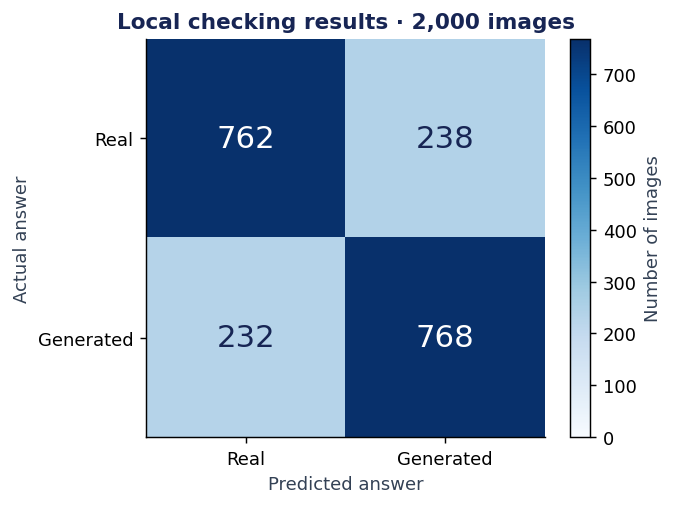

Real: 762/1000 correctly identified (76.2%)
Generated: 768/1000 correctly identified (76.8%)


In [37]:
confusion = torch.tensor(holdout_metrics['confusion_matrix'])
names = ['Real', 'Generated']
fig, ax = plt.subplots(figsize=(5.2, 4))
image = ax.imshow(confusion, cmap='Blues', vmin=0)
ax.set(xticks=range(2), yticks=range(2), xticklabels=names, yticklabels=names,
       xlabel='Predicted answer', ylabel='Actual answer', title='Local checking results · 2,000 images')
for row in range(2):
    for column in range(2):
        value = confusion[row, column].item()
        ax.text(column, row, str(value), ha='center', va='center', fontsize=17,
                color='white' if value > confusion.max().item() / 2 else '#172554')
fig.colorbar(image, ax=ax, label='Number of images')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_confusion_matrix.png', bbox_inches='tight')
plt.show()
plt.close(fig)
for index, name in enumerate(names):
    correct = confusion[index, index].item()
    total = confusion[index].sum().item()
    print(f'{name}: {correct}/{total} correctly identified ({correct / total:.1%})')

# 8. Train and save the final model

After checking the method above, I trained another fresh model using all of the 10,000 labeled images which givs the final model all available training examples.

In [38]:
model, _, _, _ = fit(images, labels, chosen_epoch, settings)
weights_path = OUTPUT_DIR / 'submission_dic.pth'
torch.save(model.state_dict(), weights_path)
(OUTPUT_DIR / 'submission_model.py').write_text('from torch import nn\n\n\nclass MyModel(nn.Module):\n\n    def __init__(self):\n        super().__init__()\n        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)\n        self.relu1 = nn.ReLU()\n        self.pool1 = nn.MaxPool2d(2)\n        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)\n        self.relu2 = nn.ReLU()\n        self.pool2 = nn.MaxPool2d(2)\n        self.fc1 = nn.Linear(64 * 8 * 8, 2)\n\n    def forward(self, x):\n        x = self.conv1(x)\n        x = self.relu1(x)\n        x = self.pool1(x)\n        x = self.conv2(x)\n        x = self.relu2(x)\n        x = self.pool2(x)\n        x = x.flatten(1)\n        x = self.fc1(x)\n        return x\n', encoding='utf-8')

Epoch 1/35: training loss=0.593792
Epoch 5/35: training loss=0.530218
Epoch 10/35: training loss=0.503007
Epoch 15/35: training loss=0.481269
Epoch 20/35: training loss=0.449919
Epoch 25/35: training loss=0.427284
Epoch 30/35: training loss=0.412165
Epoch 35/35: training loss=0.399541


635

In [39]:
restored_model = MyModel()
restored_model.load_state_dict(torch.load(weights_path, map_location='cpu', weights_only=True))
restored_model.eval()
with torch.no_grad():
    scores = restored_model(images[:4])
print('Example scores [real, generated]:')
print(scores)
print('Predicted labels:', scores.argmax(dim=1).tolist())
print('Actual labels:   ', labels[:4].tolist())
print('These four images were used for final training; this is a loading demonstration.')


Example scores [real, generated]:
tensor([[ 1.0504, -1.0707],
        [ 0.9036, -0.7553],
        [ 0.4724, -0.3352],
        [ 0.2175, -0.1182]])
Predicted labels: [0, 0, 0, 0]
Actual labels:    [0, 0, 0, 0]
These four images were used for final training; this is a loading demonstration.


In [40]:
display(Markdown(
    f'**Measured local accuracy: {holdout_metrics["accuracy"]:.2%}.** '
    f'The CNN got {holdout_metrics["correct"]:,} of {holdout_metrics["total"]:,} images correct. '
    f'It identified real images correctly {confusion[0, 0].item() / confusion[0].sum().item():.1%} of the time '
    f'and generated images correctly {confusion[1, 1].item() / confusion[1].sum().item():.1%} of the time.'
))
print('Saved files:', OUTPUT_DIR)

**Measured local accuracy: 76.50%.** The CNN got 1,530 of 2,000 images correct. It identified real images correctly 76.2% of the time and generated images correctly 76.8% of the time.

Saved files: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question2


# Conclusion and limits

The CNN model that I made got **530** more checking images correct than always choosing one label which is a total of **26.50%** increase in points. It correctly identified ``76.62% of the real images`` and ``76.6% of the generated images``. And of the 1,000 igenereated images, **232** were mistaken for real and of the 1,000 real images, **238** were mistaken for generated. This makes missed real images the larger error group on this run.

As for the limitations, since this is only a small CNN trained only on the given images from CIFAR10, the results do not establish how well it detects images from other different generators or datasets.